In [1]:
from pathlib import Path
import duckdb

current_folder = Path.cwd()
project_root = (
    current_folder.parent
    if current_folder.name == "notebooks"
    else current_folder
)

database_path = (
    project_root / "data" / "warehouse" / "customer_loyalty.duckdb"
)

if not database_path.is_file():
    raise FileNotFoundError(f"Database not found: {database_path}")

con = duckdb.connect(str(database_path))

print(f"Connected to: {database_path}")

Connected to: /Users/faridoonfarahi/Documents/Personal_Projects/customer_loyalty_platform/data/warehouse/customer_loyalty.duckdb


In [2]:
analysis_campaign_id = 18

campaign_details = con.sql(
    """
    SELECT
        c.CAMPAIGN,
        c.DESCRIPTION,
        c.START_DAY,
        c.END_DAY,
        COUNT(DISTINCT ct.household_key) AS targeted_households
    FROM campaigns AS c
    LEFT JOIN campaign_targets AS ct
        ON c.CAMPAIGN = ct.CAMPAIGN
    WHERE c.CAMPAIGN = ?
    GROUP BY
        c.CAMPAIGN, c.DESCRIPTION, c.START_DAY, c.END_DAY
    """,
    params=[analysis_campaign_id]
).df()

campaign_details

,CAMPAIGN,DESCRIPTION,START_DAY,END_DAY,targeted_households
0,18,TypeA,587,642,1133


In [3]:
campaign_start_day = int(campaign_details.loc[0, "START_DAY"])
campaign_end_day = int(campaign_details.loc[0, "END_DAY"])

measurement_days = campaign_end_day - campaign_start_day + 1

pre_end_day = campaign_start_day - 1
pre_start_day = campaign_start_day - measurement_days

print(f"Before campaign: days {pre_start_day}–{pre_end_day}")
print(f"During campaign: days {campaign_start_day}–{campaign_end_day}")
print(f"Days in each period: {measurement_days}")

Before campaign: days 531–586
During campaign: days 587–642
Days in each period: 56


In [4]:
campaign_cohort = con.sql(
    """
    WITH prior_households AS (
        SELECT DISTINCT household_key
        FROM transactions
        WHERE DAY < ?
    )
    SELECT
        h.household_key,
        CASE
            WHEN ct.household_key IS NOT NULL THEN 1
            ELSE 0
        END AS targeted
    FROM prior_households AS h
    LEFT JOIN campaign_targets AS ct
        ON h.household_key = ct.household_key
       AND ct.CAMPAIGN = ?
    ORDER BY h.household_key
    """,
    params=[pre_start_day, analysis_campaign_id]
).df()

campaign_cohort.groupby("targeted").size().rename("households")

targeted
0    1365
1    1133
Name: households, dtype: int64

In [5]:
con.register("study_cohort", campaign_cohort)

other_campaign_exposure = con.sql(
    """
    SELECT
        h.household_key,
        h.targeted,
        COUNT(DISTINCT c.CAMPAIGN) AS other_overlapping_campaigns
    FROM study_cohort AS h
    LEFT JOIN campaign_targets AS ct
        ON h.household_key = ct.household_key
       AND ct.CAMPAIGN <> ?
    LEFT JOIN campaigns AS c
        ON ct.CAMPAIGN = c.CAMPAIGN
       AND c.START_DAY <= ?
       AND c.END_DAY >= ?
    GROUP BY h.household_key, h.targeted
    """,
    params=[
        analysis_campaign_id,
        campaign_end_day,
        campaign_start_day
    ]
).df()

other_campaign_exposure.groupby("targeted").agg(
    households=("household_key", "size"),
    households_with_other_campaigns=(
        "other_overlapping_campaigns",
        lambda counts: (counts > 0).sum()
    ),
    mean_other_campaigns=("other_overlapping_campaigns", "mean")
).round(2)

,households,households_with_other_campaigns,mean_other_campaigns
targeted,,,
0,1365,116,0.12
1,1133,623,1.05


In [6]:
pre_campaign_features = con.sql(
    """
    SELECT
        h.household_key,
        h.targeted,
        COALESCE(SUM(t.SALES_VALUE), 0) AS sales_before,
        COUNT(DISTINCT t.BASKET_ID) AS baskets_before,
        COUNT(DISTINCT t.DAY) AS active_days_before
    FROM study_cohort AS h
    LEFT JOIN transactions AS t
        ON h.household_key = t.household_key
       AND t.DAY BETWEEN ? AND ?
    GROUP BY h.household_key, h.targeted
    """,
    params=[pre_start_day, pre_end_day]
).df()

pre_campaign_features.groupby("targeted").agg(
    households=("household_key", "size"),
    mean_sales_before=("sales_before", "mean"),
    median_sales_before=("sales_before", "median"),
    mean_active_days_before=("active_days_before", "mean")
).round(2)

,households,mean_sales_before,median_sales_before,mean_active_days_before
targeted,,,,
0,1365,140.12,67.72,4.31
1,1133,435.95,351.82,12.00


In [7]:
during_campaign_features = con.sql(
    """
    SELECT
        h.household_key,
        h.targeted,
        COALESCE(SUM(t.SALES_VALUE), 0) AS sales_during,
        COUNT(DISTINCT t.BASKET_ID) AS baskets_during,
        COUNT(DISTINCT t.DAY) AS active_days_during
    FROM study_cohort AS h
    LEFT JOIN transactions AS t
        ON h.household_key = t.household_key
       AND t.DAY BETWEEN ? AND ?
    GROUP BY h.household_key, h.targeted
    """,
    params=[campaign_start_day, campaign_end_day]
).df()

campaign_outcomes = pre_campaign_features.merge(
    during_campaign_features,
    on=["household_key", "targeted"],
    validate="one_to_one"
)

campaign_outcomes.groupby("targeted").agg(
    households=("household_key", "size"),
    mean_sales_before=("sales_before", "mean"),
    mean_sales_during=("sales_during", "mean")
).round(2)

,households,mean_sales_before,mean_sales_during
targeted,,,
0,1365,140.12,159.92
1,1133,435.95,470.67


In [8]:
campaign_outcomes["sales_change"] = (
    campaign_outcomes["sales_during"]
    - campaign_outcomes["sales_before"]
)

mean_changes = campaign_outcomes.groupby("targeted")["sales_change"].mean()

difference_in_changes = mean_changes.loc[1] - mean_changes.loc[0]

print(f"Targeted group mean change: {mean_changes.loc[1]:.2f}")
print(f"Comparison group mean change: {mean_changes.loc[0]:.2f}")
print(f"Difference in mean changes: {difference_in_changes:.2f}")

Targeted group mean change: 34.72
Comparison group mean change: 19.80
Difference in mean changes: 14.92


In [9]:
pre_campaign_trends = con.sql(
    """
    SELECT
        w.week_index + 1 AS pre_campaign_week,
        h.targeted,
        COALESCE(SUM(t.SALES_VALUE), 0)
            / COUNT(DISTINCT h.household_key) AS mean_sales_per_household
    FROM study_cohort AS h
    CROSS JOIN range(8) AS w(week_index)
    LEFT JOIN transactions AS t
        ON h.household_key = t.household_key
       AND t.DAY BETWEEN
           ? + 7 * w.week_index
           AND ? + 7 * w.week_index + 6
    GROUP BY w.week_index, h.targeted
    ORDER BY w.week_index, h.targeted
    """,
    params=[pre_start_day, pre_start_day]
).df()

pre_campaign_trends.pivot(
    index="pre_campaign_week",
    columns="targeted",
    values="mean_sales_per_household"
).round(2)

targeted,0,1
pre_campaign_week,,
1,19.65,57.67
2,16.19,52.08
3,16.18,53.31
4,16.47,53.60
5,19.76,55.78
6,17.60,55.53
7,15.72,54.50
8,18.56,53.49


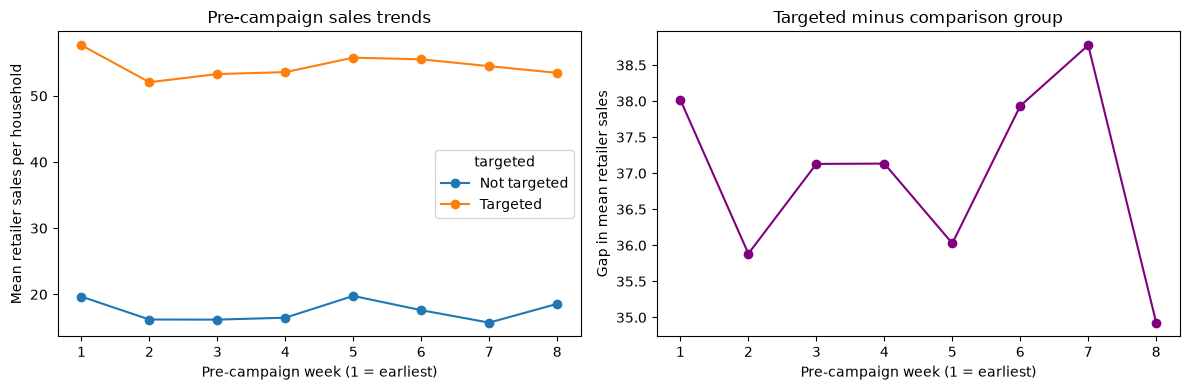

In [10]:
import matplotlib.pyplot as plt

trend_table = pre_campaign_trends.pivot(
    index="pre_campaign_week",
    columns="targeted",
    values="mean_sales_per_household"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

trend_table.rename(
    columns={0: "Not targeted", 1: "Targeted"}
).plot(marker="o", ax=axes[0])

axes[0].set_title("Pre-campaign sales trends")
axes[0].set_ylabel("Mean retailer sales per household")

(trend_table[1] - trend_table[0]).plot(
    marker="o", ax=axes[1], color="purple"
)

axes[1].set_title("Targeted minus comparison group")
axes[1].set_ylabel("Gap in mean retailer sales")

for ax in axes:
    ax.set_xlabel("Pre-campaign week (1 = earliest)")

fig.tight_layout()

campaign_report_folder = project_root / "reports" / "campaign_effectiveness"
campaign_report_folder.mkdir(parents=True, exist_ok=True)

fig.savefig(
    campaign_report_folder / f"campaign_{analysis_campaign_id}_pretrends.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [11]:
import numpy as np

targeted_changes = campaign_outcomes.loc[
    campaign_outcomes["targeted"] == 1, "sales_change"
].to_numpy()

comparison_changes = campaign_outcomes.loc[
    campaign_outcomes["targeted"] == 0, "sales_change"
].to_numpy()

rng = np.random.default_rng(42)
bootstrap_differences = np.empty(2000)

for i in range(len(bootstrap_differences)):
    targeted_sample = rng.choice(
        targeted_changes, size=len(targeted_changes), replace=True
    )
    comparison_sample = rng.choice(
        comparison_changes, size=len(comparison_changes), replace=True
    )

    bootstrap_differences[i] = (
        targeted_sample.mean() - comparison_sample.mean()
    )

ci_lower, ci_upper = np.quantile(
    bootstrap_differences, [0.025, 0.975]
)

print(f"Observed difference in changes: {difference_in_changes:.2f}")
print(f"95% household-bootstrap interval: [{ci_lower:.2f}, {ci_upper:.2f}]")

Observed difference in changes: 14.92
95% household-bootstrap interval: [0.74, 29.25]


In [12]:
import pandas as pd

balance_rows = []

for feature in ["sales_before", "active_days_before"]:
    targeted_values = campaign_outcomes.loc[
        campaign_outcomes["targeted"] == 1, feature
    ]
    comparison_values = campaign_outcomes.loc[
        campaign_outcomes["targeted"] == 0, feature
    ]

    pooled_sd = np.sqrt(
        (targeted_values.var() + comparison_values.var()) / 2
    )

    balance_rows.append({
        "feature": feature,
        "targeted_mean": targeted_values.mean(),
        "comparison_mean": comparison_values.mean(),
        "standardized_difference": (
            targeted_values.mean() - comparison_values.mean()
        ) / pooled_sd
    })

baseline_balance = pd.DataFrame(balance_rows)
baseline_balance.round(3)

,feature,targeted_mean,comparison_mean,standardized_difference
0,sales_before,435.949,140.119,0.987
1,active_days_before,11.996,4.311,1.118


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression

propensity_features = ["sales_before", "active_days_before"]

propensity_model = Pipeline([
    ("log_transform", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

propensity_model.fit(
    campaign_outcomes[propensity_features],
    campaign_outcomes["targeted"]
)

campaign_outcomes["targeting_propensity"] = (
    propensity_model.predict_proba(
        campaign_outcomes[propensity_features]
    )[:, 1]
)

campaign_outcomes.groupby("targeted")["targeting_propensity"].describe(
    percentiles=[0.1, 0.5, 0.9]
).round(3)

,count,mean,std,min,10%,50%,90%,max
targeted,,,,,,,,
0,1365.0,0.304,0.243,0.02,0.020,0.271,0.670,0.956
1,1133.0,0.634,0.209,0.02,0.336,0.685,0.861,0.953


In [14]:
propensity_bands = pd.cut(
    campaign_outcomes["targeting_propensity"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

overlap_counts = pd.crosstab(
    propensity_bands,
    campaign_outcomes["targeted"],
    dropna=False
).rename(columns={
    0: "Not targeted",
    1: "Targeted"
})

overlap_counts

targeted,Not targeted,Targeted
targeting_propensity,,
"(-0.001, 0.1]",363,34
"(0.1, 0.2]",213,26
"(0.2, 0.3]",162,31
"(0.3, 0.4]",181,69
"(0.4, 0.5]",132,96
"(0.5, 0.6]",122,151
"(0.6, 0.7]",76,198
"(0.7, 0.8]",65,272
"(0.8, 0.9]",45,202


In [15]:
campaign_outcomes["overlap_weight"] = np.where(
    campaign_outcomes["targeted"] == 1,
    1 - campaign_outcomes["targeting_propensity"],
    campaign_outcomes["targeting_propensity"]
)

weight_summary = campaign_outcomes.groupby("targeted")[
    "overlap_weight"
].agg(
    households="size",
    total_weight="sum",
    minimum_weight="min",
    maximum_weight="max",
    effective_sample_size=lambda w: w.sum() ** 2 / (w ** 2).sum()
)

weight_summary.round(2)

,households,total_weight,minimum_weight,maximum_weight,effective_sample_size
targeted,,,,,
0,1365,415.04,0.02,0.96,833.11
1,1133,415.00,0.05,0.98,854.29


In [16]:
balance_features = campaign_outcomes[propensity_features].copy()

for feature in propensity_features:
    balance_features[f"log1p_{feature}"] = np.log1p(
        campaign_outcomes[feature]
    )

targeted_mask = campaign_outcomes["targeted"].eq(1)
weighted_balance_rows = []

for feature in balance_features.columns:
    x1 = balance_features.loc[targeted_mask, feature]
    x0 = balance_features.loc[~targeted_mask, feature]

    w1 = campaign_outcomes.loc[targeted_mask, "overlap_weight"]
    w0 = campaign_outcomes.loc[~targeted_mask, "overlap_weight"]

    pooled_sd = np.sqrt((x1.var() + x0.var()) / 2)

    weighted_balance_rows.append({
        "feature": feature,
        "unweighted_standardized_difference": (
            x1.mean() - x0.mean()
        ) / pooled_sd,
        "weighted_standardized_difference": (
            np.average(x1, weights=w1)
            - np.average(x0, weights=w0)
        ) / pooled_sd
    })

weighted_balance = pd.DataFrame(weighted_balance_rows)
weighted_balance.round(3)

,feature,unweighted_standardized_difference,weighted_standardized_difference
0,sales_before,0.987,0.089
1,active_days_before,1.118,0.017
2,log1p_sales_before,1.183,0.002
3,log1p_active_days_before,1.347,0.003


In [17]:
weighted_targeted_change = np.average(
    campaign_outcomes.loc[targeted_mask, "sales_change"],
    weights=campaign_outcomes.loc[targeted_mask, "overlap_weight"]
)

weighted_comparison_change = np.average(
    campaign_outcomes.loc[~targeted_mask, "sales_change"],
    weights=campaign_outcomes.loc[~targeted_mask, "overlap_weight"]
)

weighted_difference_in_changes = (
    weighted_targeted_change - weighted_comparison_change
)

print(f"Weighted targeted mean change: {weighted_targeted_change:.2f}")
print(f"Weighted comparison mean change: {weighted_comparison_change:.2f}")
print(f"Weighted difference in changes: {weighted_difference_in_changes:.2f}")

Weighted targeted mean change: 49.43
Weighted comparison mean change: 1.98
Weighted difference in changes: 47.46


In [18]:
exposure_review = campaign_outcomes[
    ["household_key", "targeted", "overlap_weight"]
].merge(
    other_campaign_exposure,
    on=["household_key", "targeted"],
    validate="one_to_one"
)

weighted_exposure_rows = []

for targeted, group in exposure_review.groupby("targeted"):
    exposed = group["other_overlapping_campaigns"] > 0

    weighted_exposure_rows.append({
        "targeted": targeted,
        "unweighted_other_campaign_pct": exposed.mean() * 100,
        "weighted_other_campaign_pct": np.average(
            exposed.astype(float),
            weights=group["overlap_weight"]
        ) * 100
    })

pd.DataFrame(weighted_exposure_rows).round(2)

,targeted,unweighted_other_campaign_pct,weighted_other_campaign_pct
0,0,8.50,16.23
1,1,54.99,44.97


In [19]:
from sklearn.base import clone

def estimate_overlap_contrast(data):
    estimator = clone(propensity_model)

    estimator.fit(
        data[propensity_features],
        data["targeted"]
    )

    propensity = estimator.predict_proba(
        data[propensity_features]
    )[:, 1]

    targeted = data["targeted"].eq(1).to_numpy()
    changes = data["sales_change"].to_numpy()

    weights = np.where(targeted, 1 - propensity, propensity)

    return (
        np.average(changes[targeted], weights=weights[targeted])
        - np.average(changes[~targeted], weights=weights[~targeted])
    )

print(
    f"Recalculated weighted contrast: "
    f"{estimate_overlap_contrast(campaign_outcomes):.2f}"
)

Recalculated weighted contrast: 47.46


In [20]:
targeted_rows = campaign_outcomes.loc[
    campaign_outcomes["targeted"] == 1
]
comparison_rows = campaign_outcomes.loc[
    campaign_outcomes["targeted"] == 0
]

weighted_rng = np.random.default_rng(42)
weighted_bootstrap_differences = np.empty(2000)

for i in range(len(weighted_bootstrap_differences)):
    sampled_targeted = targeted_rows.iloc[
        weighted_rng.integers(
            0, len(targeted_rows), size=len(targeted_rows)
        )
    ]
    sampled_comparison = comparison_rows.iloc[
        weighted_rng.integers(
            0, len(comparison_rows), size=len(comparison_rows)
        )
    ]

    bootstrap_sample = pd.concat(
        [sampled_targeted, sampled_comparison],
        ignore_index=True
    )

    weighted_bootstrap_differences[i] = estimate_overlap_contrast(
        bootstrap_sample
    )

    if (i + 1) % 500 == 0:
        print(f"Completed {i + 1:,} bootstrap samples")

weighted_ci_lower, weighted_ci_upper = np.quantile(
    weighted_bootstrap_differences, [0.025, 0.975]
)

print(
    f"95% weighted household-bootstrap interval: "
    f"[{weighted_ci_lower:.2f}, {weighted_ci_upper:.2f}]"
)

Completed 500 bootstrap samples
Completed 1,000 bootstrap samples
Completed 1,500 bootstrap samples
Completed 2,000 bootstrap samples
95% weighted household-bootstrap interval: [30.95, 64.43]


In [21]:
campaign_result_summary = pd.DataFrame([
    {
        "method": "Unweighted difference in changes",
        "population": "Full study cohort",
        "sales_change_contrast": difference_in_changes,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    },
    {
        "method": "Overlap-weighted difference in changes",
        "population": "Overlap-weighted study cohort",
        "sales_change_contrast": weighted_difference_in_changes,
        "ci_lower": weighted_ci_lower,
        "ci_upper": weighted_ci_upper
    }
])

campaign_result_summary.insert(0, "campaign_id", analysis_campaign_id)
campaign_result_summary["interpretation"] = "Observational association"
campaign_result_summary["bootstrap_samples"] = 2000

summary_path = (
    campaign_report_folder
    / f"campaign_{analysis_campaign_id}_observational_results.csv"
)

campaign_result_summary.to_csv(summary_path, index=False)

print(f"Saved observational results: {summary_path}")

Saved observational results: /Users/faridoonfarahi/Documents/Personal_Projects/customer_loyalty_platform/reports/campaign_effectiveness/campaign_18_observational_results.csv


In [22]:
campaign_analysis_table = campaign_outcomes.merge(
    other_campaign_exposure,
    on=["household_key", "targeted"],
    how="left",
    validate="one_to_one"
)

campaign_analysis_table["CAMPAIGN"] = analysis_campaign_id
campaign_analysis_table["pre_start_day"] = pre_start_day
campaign_analysis_table["pre_end_day"] = pre_end_day
campaign_analysis_table["campaign_start_day"] = campaign_start_day
campaign_analysis_table["campaign_end_day"] = campaign_end_day

analysis_table_path = (
    project_root / "data" / "processed"
    / f"campaign_{analysis_campaign_id}_household_analysis.parquet"
)

campaign_analysis_table.to_parquet(analysis_table_path, index=False)

print(f"Saved household records: {len(campaign_analysis_table):,}")
print(
    "Missing other-campaign exposure counts:",
    campaign_analysis_table["other_overlapping_campaigns"].isna().sum()
)

Saved household records: 2,498
Missing other-campaign exposure counts: 0


In [23]:
diagnostic_tables = {
    "baseline_balance": baseline_balance,
    "weighted_balance": weighted_balance,
    "weight_summary": weight_summary.reset_index(),
    "propensity_overlap_counts": overlap_counts.reset_index(),
    "other_campaign_exposure": pd.DataFrame(weighted_exposure_rows),
    "pre_campaign_weekly_sales": pre_campaign_trends
}

for name, table in diagnostic_tables.items():
    output_path = (
        campaign_report_folder
        / f"campaign_{analysis_campaign_id}_{name}.csv"
    )

    table.to_csv(output_path, index=False)
    print(f"Saved: {output_path.name}")

Saved: campaign_18_baseline_balance.csv
Saved: campaign_18_weighted_balance.csv
Saved: campaign_18_weight_summary.csv
Saved: campaign_18_propensity_overlap_counts.csv
Saved: campaign_18_other_campaign_exposure.csv
Saved: campaign_18_pre_campaign_weekly_sales.csv


In [24]:
con.close()